<a href="https://colab.research.google.com/github/Shahbazhashmi04/superstore-sales-forecasting/blob/main/Regional_Sales_Forecasting_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded=files.upload()

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
shahbaz=pd.read_csv('superstore_dataset.csv')

**Data Pre-processing**

In [ ]:
shahbaz.head(5)

,order_id,order_date,ship_date,customer,manufactory,product_name,segment,category,subcategory,region,zip,city,state,country,discount,profit,quantity,sales,profit_margin
0,US-2023-107503,1/1/2022,1/6/2022,Guy Armstrong,Linden,"Linden 10"" Round Wall Clock, Black",Consumer,Furniture,Furnishings,East,44052,Lorain,Ohio,United States,0.2,8.5568,4,48.896,0.175000
1,US-2023-144463,1/1/2022,1/5/2022,Steven Cartwright,Howard Miller,"Howard Miller 11-1/2"" Diameter Brentwood Wall ...",Consumer,Furniture,Furnishings,West,90036,Los Angeles,California,United States,0.0,199.2606,11,474.430,0.420000
2,US-2023-151750,1/1/2022,1/5/2022,Janet Martin,Office Star,Office Star - Contemporary Task Swivel Chair,Consumer,Furniture,Chairs,Central,77340,Huntsville,Texas,United States,0.3,-26.6352,4,310.744,-0.085714
3,US-2023-151750,1/1/2022,1/5/2022,Janet Martin,Tenex,"Tenex Carpeted, Granite-Look or Clear Contempo...",Consumer,Furniture,Furnishings,Central,77340,Huntsville,Texas,United States,0.6,-187.3815,5,141.420,-1.325000
4,US-2023-151750,1/1/2022,1/5/2022,Janet Martin,Fellowes,Fellowes Superior 10 Outlet Split Surge Protector,Consumer,Office Supplies,Appliances,Central,77340,Huntsville,Texas,United States,0.8,-38.8212,2,15.224,-2.550000


In [ ]:
shahbaz.tail(5)

,order_id,order_date,ship_date,customer,manufactory,product_name,segment,category,subcategory,region,zip,city,state,country,discount,profit,quantity,sales,profit_margin
3307,US-2023-126221,12/30/2022,1/5/2023,Chuck Clark,Eureka,Eureka The Boss Plus 12-Amp Hard Box Upright V...,Home Office,Office Supplies,Appliances,Central,47201,Columbus,Indiana,United States,0.0,56.5110,2,209.300,0.2700
3308,US-2023-143259,12/30/2022,1/3/2023,Patrick O'Donnell,Other,"Bush Westfield Collection Bookcases, Fully Ass...",Consumer,Furniture,Bookcases,East,10009,New York City,New York,United States,0.2,12.1176,4,323.136,0.0375
3309,US-2023-143259,12/30/2022,1/3/2023,Patrick O'Donnell,Wilson Jones,Wilson Jones Legal Size Ring Binders,Consumer,Office Supplies,Binders,East,10009,New York City,New York,United States,0.2,19.7910,3,52.776,0.3750
3310,US-2023-143259,12/30/2022,1/3/2023,Patrick O'Donnell,Other,Gear Head AU3700S Headset,Consumer,Technology,Phones,East,10009,New York City,New York,United States,0.0,2.7279,7,90.930,0.0300
3311,US-2023-156720,12/30/2022,1/3/2023,Jill Matthias,Other,Bagged Rubber Bands,Consumer,Office Supplies,Fasteners,West,80538,Loveland,Colorado,United States,0.2,-0.6048,3,3.024,-0.2000


In [ ]:
shahbaz.shape
#19 Features
#3312 Observations

(3312, 19)

In [ ]:
shahbaz.describe()

,zip,discount,profit,quantity,sales,profit_margin
count,3312.000000,3312.000000,3312.000000,3312.000000,3312.000000,3312.000000
mean,56186.504529,0.156467,28.212340,3.766908,221.381418,0.115981
std,31980.392301,0.207429,241.864342,2.221776,585.257531,0.481265
min,1841.000000,0.000000,-3839.990400,1.000000,0.444000,-2.750000
25%,27978.750000,0.000000,1.763200,2.000000,17.018000,0.075000
50%,60472.500000,0.200000,8.296800,3.000000,53.810000,0.270000
75%,90032.000000,0.200000,28.315125,5.000000,205.105700,0.362500
max,99301.000000,0.800000,6719.980800,14.000000,13999.960000,0.500000


In [ ]:
shahbaz.columns

Index(['order_id', 'order_date', 'ship_date', 'customer', 'manufactory',
       'product_name', 'segment', 'category', 'subcategory', 'region', 'zip',
       'city', 'state', 'country', 'discount', 'profit', 'quantity', 'sales',
       'profit_margin'],
      dtype='object')

In [ ]:
shahbaz.isnull().sum()


,0
order_id,0
order_date,0
ship_date,0
customer,0
manufactory,0
product_name,0
segment,0
category,0
subcategory,0
region,0


**Data Visualization**

<Axes: >

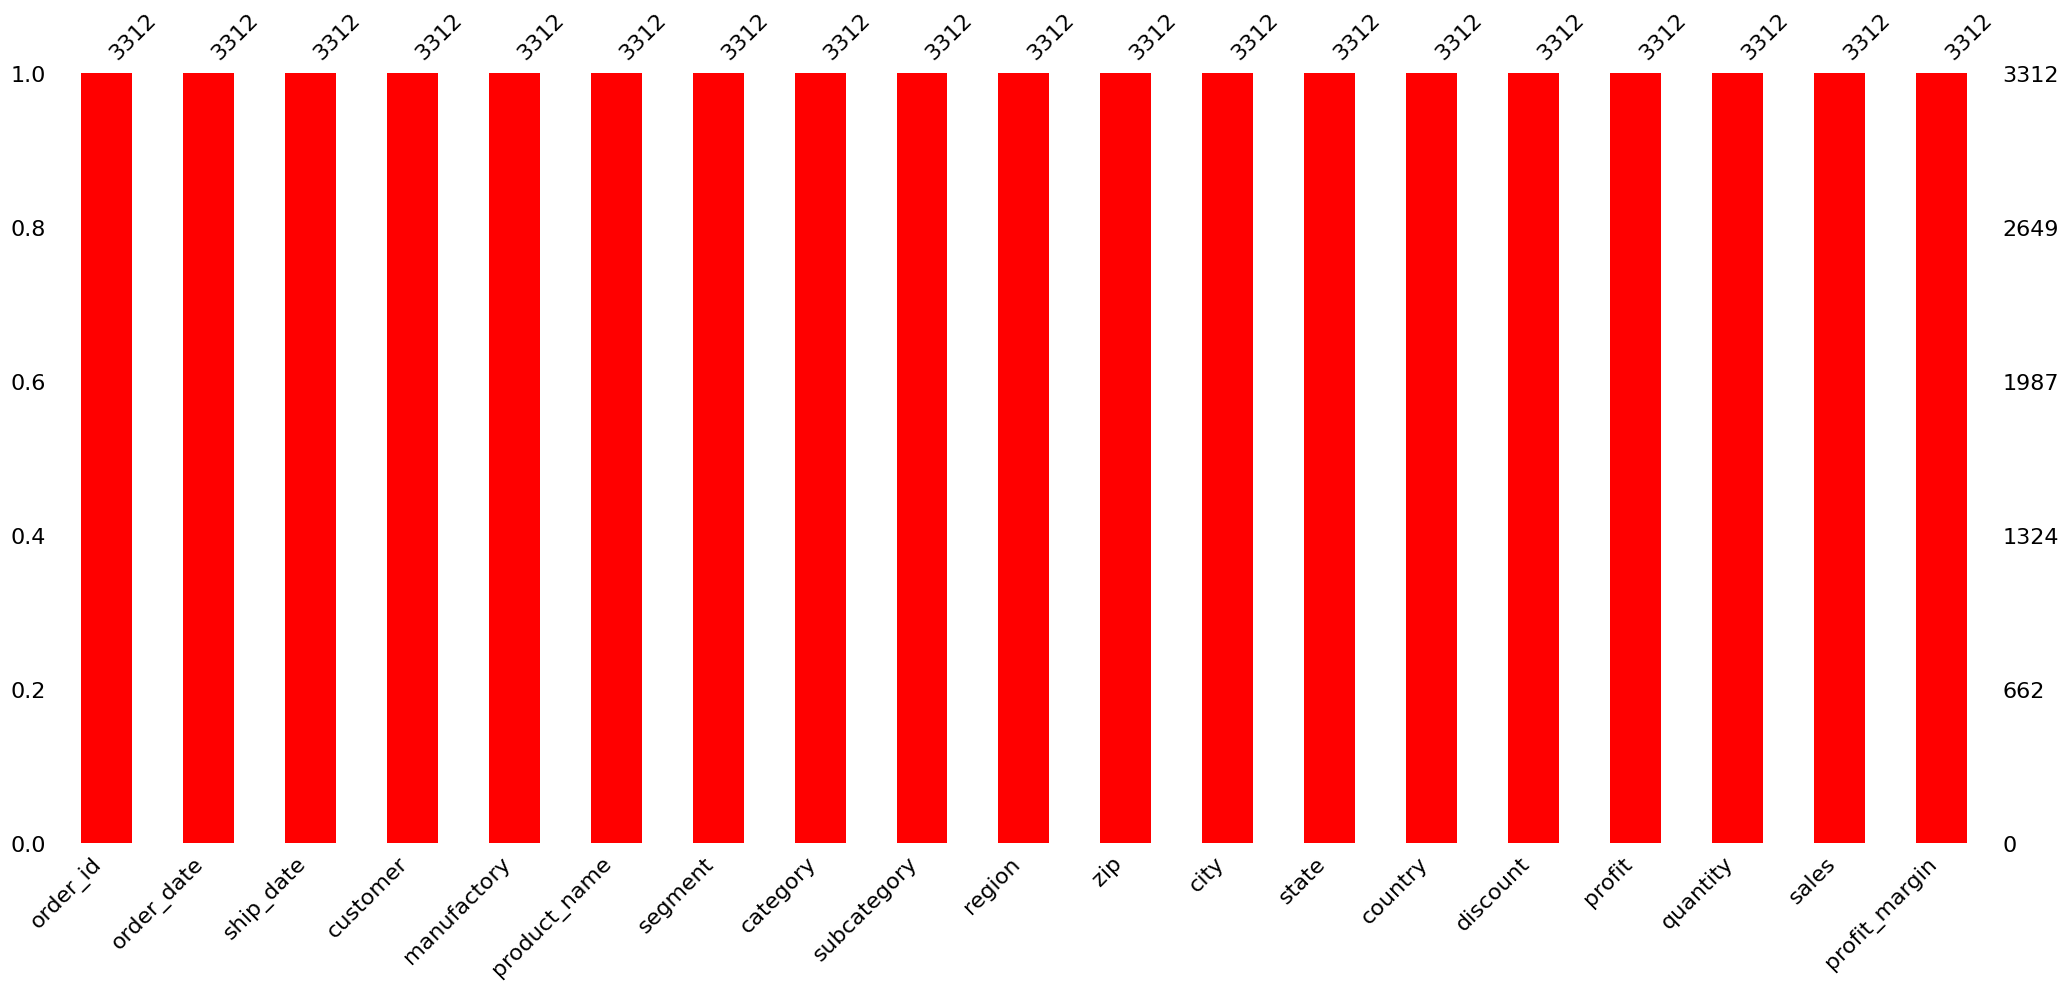

In [ ]:
import missingno as msno
msno.bar(shahbaz,color='red')

**Check duplication**

In [ ]:
shahbaz.duplicated().sum()

0

Dropping Unnecessary Columns from the Dataset

In [ ]:
shahbaz.columns

Index(['order_id', 'order_date', 'ship_date', 'customer', 'manufactory',
       'product_name', 'segment', 'category', 'subcategory', 'region', 'zip',
       'city', 'state', 'country', 'discount', 'profit', 'quantity', 'sales',
       'profit_margin'],
      dtype='object')

In [ ]:
shahbaz.drop(['order_id', 'ship_date', 'customer', 'manufactory',
       'product_name', 'segment', 'zip',
       'city', 'state', 'country', 'profit'], axis=1, inplace=True)


In [ ]:
shahbaz.columns

Index(['order_date', 'category', 'subcategory', 'region', 'discount',
       'quantity', 'sales', 'profit_margin'],
      dtype='object')

In [ ]:
#cross check after drop
shahbaz.shape

(3312, 8)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt #import matplot library

In [ ]:
def detect_outliers(df,column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
  return outliers

numerical_data = shahbaz.select_dtypes(include=[np.number])

for col in numerical_data.columns:
  outliers = detect_outliers(shahbaz, col)
  print(f"Number of Outliers in column '{col}':{len(outliers)}")

Number of Outliers in column 'discount':284
Number of Outliers in column 'quantity':54
Number of Outliers in column 'sales':366
Number of Outliers in column 'profit_margin':315


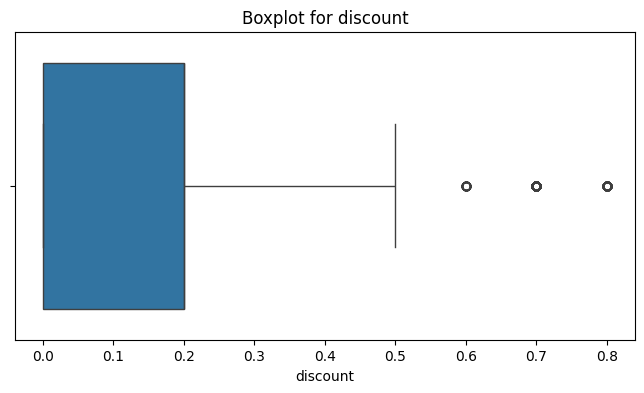

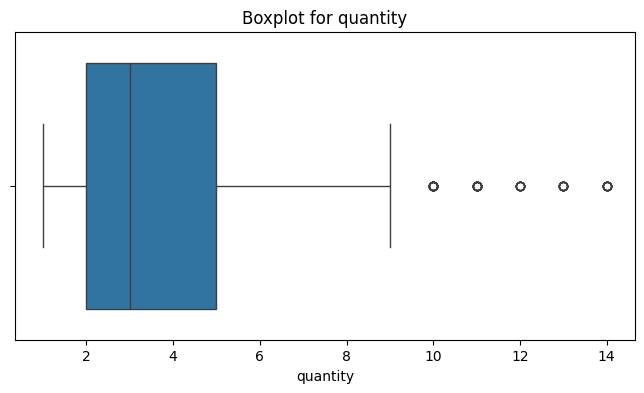

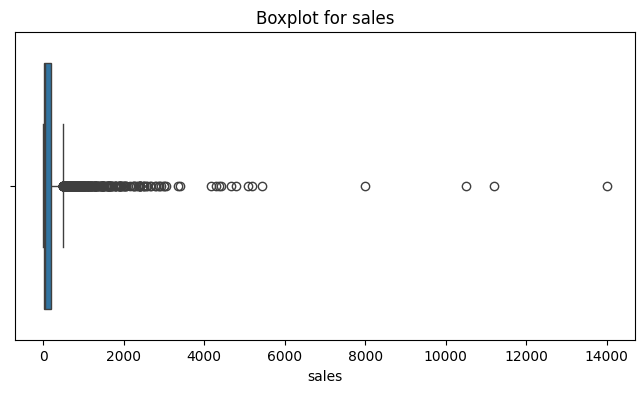

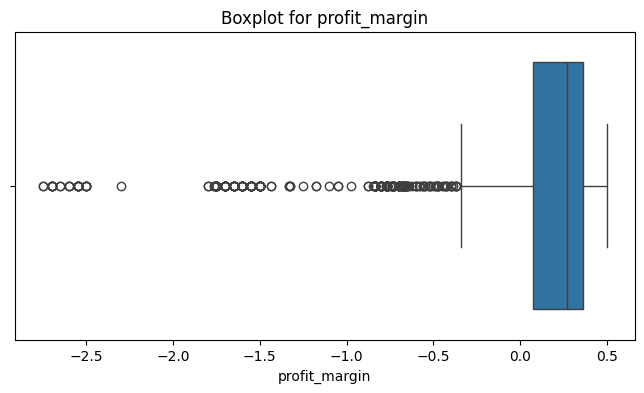

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numerical_data.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=shahbaz, x=col)
    plt.title(f'Boxplot for {col}')
    plt.show()


**Removing Outliers**

In [ ]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

for col in numerical_data.columns:
    shahbaz = remove_outliers(shahbaz, col)


**Verification of Outliers**

In [ ]:
for col in numerical_data.columns:
    outliers = detect_outliers(shahbaz, col)
    print(f"Number of Outliers in column '{col}': {len(outliers)}")


Number of Outliers in column 'discount': 0
Number of Outliers in column 'quantity': 0
Number of Outliers in column 'sales': 0
Number of Outliers in column 'profit_margin': 0


**Removing Remaining Outliers**

In [ ]:
for col in ['sales']:
    shahbaz = remove_outliers(shahbaz, col)


**1.Splitting Dataset**

In [ ]:
from sklearn.model_selection import train_test_split

# Features (excluding the target 'sales' and unnecessary columns)
X = shahbaz.drop(columns=['sales', 'order_date'])
y = shahbaz['sales']

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


**2. Encoding Categorical Variables**

In [ ]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

**3. Feature Scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Implementing Machine Learning Models**

In [ ]:
#SUM MODEL
!pip install --upgrade scikit-learn
# Restart the runtime/kernel after upgrading scikit-learn

# Import after the upgrade/restart
from sklearn.metrics import mean_squared_error, r2_score

# Assuming 'y_pred_sum' should hold the sum of some values
# Replace this with the actual logic of your SUM model
y_pred_sum = y_train.mean()  # Example: predicting the mean for all test instances


# Calculate RMSE
# The 'squared' argument has been removed in newer versions of scikit-learn.
# Use this approach to calculate RMSE:
rmse_sum = mean_squared_error(y_test, [y_pred_sum] * len(y_test))**0.5  # len(y_test) to create the appropriate list with the same size than y_test and a constant value.
r2_sum = r2_score(y_test, [y_pred_sum] * len(y_test))  # len(y_test) to create the appropriate list with the same size than y_test and a constant value.


print(f"SUM Model RMSE: {rmse_sum}")
print(f"SUM Model R^2: {r2_sum}")

SUM Model RMSE: 18.967121521322767
SUM Model R^2: -0.0006629532213533462


KNN Model RMSE: 16.96379826057403
KNN Model R^2: 0.1995556081317521


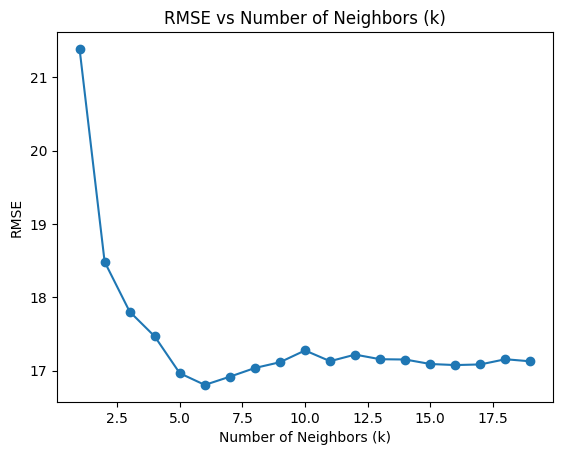

In [ ]:
#KNN MODEL

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize KNN with 5 neighbors
knn = KNeighborsRegressor(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict sales
y_pred_knn = knn.predict(X_test)

# Calculate RMSE and R^2
# The 'squared' argument has been removed. Calculate RMSE using **0.5
rmse_knn = mean_squared_error(y_test, y_pred_knn)**0.5
r2_knn = r2_score(y_test, y_pred_knn)

print(f"KNN Model RMSE: {rmse_knn}")
print(f"KNN Model R^2: {r2_knn}")

# Test different values of k
rmse_values = []
for k in range(1, 20):
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_knn = knn.predict(X_test)
    # Calculate RMSE using **0.5 in the loop as well
    rmse_values.append(mean_squared_error(y_test, y_pred_knn)**0.5)

# Plot RMSE for different k values
import matplotlib.pyplot as plt

plt.plot(range(1, 20), rmse_values, marker='o')
plt.title('RMSE vs Number of Neighbors (k)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('RMSE')
plt.show()

In [ ]:
#RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestRegressor

# Initialize and train Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict sales
y_pred_rf = rf.predict(X_test)

# Evaluate Random Forest
rmse_rf = mean_squared_error(y_test, y_pred_rf)**0.5
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest Model RMSE: {rmse_rf}")
print(f"Random Forest Model R^2: {r2_rf}")


Random Forest Model RMSE: 16.337163816686168
Random Forest Model R^2: 0.25759943146249986


In [ ]:
#DECISION TREE MODEL
from sklearn.tree import DecisionTreeRegressor

# Train Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

# Predict and evaluate
y_pred_dt = dt.predict(X_test)
rmse_dt = mean_squared_error(y_test, y_pred_dt)**0.5
r2_dt = r2_score(y_test, y_pred_dt)

print(f"Decision Tree Model RMSE: {rmse_dt}")
print(f"Decision Tree Model R^2: {r2_dt}")


Decision Tree Model RMSE: 20.35546765249934
Decision Tree Model R^2: -0.15251646100390093


Since the Decision Tree model performs worse than the baseline, it should not be considered for final predictions.

Random Forest provides the best performance (lowest RMSE and highest R²).
It should be selected as the final model for your Regional Sales Forecasting project.

**Plotting Actual VS Predicted Sales Plot For Random Forest Model**

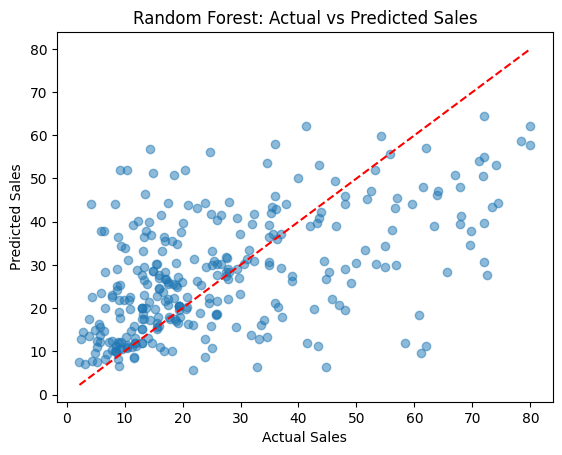

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Random Forest: Actual vs Predicted Sales')
plt.show()


In [ ]:
!pip install tabulate
from tabulate import tabulate

print(tabulate(models_sorted, headers='keys', tablefmt='grid'))

models = pd.DataFrame({
    'Model': ['SUM Model', 'KNN Model', 'Random Forest', 'Decision Tree'],
    'RMSE': [18.96, 16.96, 16.33, 20.36],
    'R2 Score': [-0.0007, 0.199, 0.258, -0.153]
})




+----+---------------+--------+------------+
|    | Model         |   RMSE |   R2 Score |
+====+===============+========+============+
|  2 | Random Forest |  16.33 |     0.258  |
+----+---------------+--------+------------+
|  1 | KNN Model     |  16.96 |     0.199  |
+----+---------------+--------+------------+
|  0 | SUM Model     |  18.96 |    -0.0007 |
+----+---------------+--------+------------+
|  3 | Decision Tree |  20.36 |    -0.153  |
+----+---------------+--------+------------+


**1. Final Evaluation and Interpretation**

The Random Forest model achieved an RMSE of 16.33 and an R² of 0.258, demonstrating its effectiveness in capturing regional sales trends compared to other models.